# Housing market in Rennes: what happened when mortgage rates went up?

**Objective:** with every property sale registered in Ille-et-Vilaine (the département of Rennes), see how prices and number of sales changed between 2021 and 2025, when French mortgage rates went from around 1% to more than 3.5%, and estimate a hedonic model of the price (how much each characteristic of a dwelling is worth).

**Data:**
- DVF (Demandes de Valeurs Foncières) geolocalised, DGFiP / Etalab (data.gouv.fr), département 35
- Interest rate of new house purchase loans in France (ECB, MFI interest rate statistics)

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `requests` and `statsmodels`.

## Part 1. Libraries

In [1]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import statsmodels.formula.api as smf

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## Part 2. Download DVF

One file per year. We only keep the columns we need.

In [2]:
cols = ["id_mutation", "date_mutation", "nature_mutation", "valeur_fonciere", "code_commune", "nom_commune",
        "type_local", "surface_reelle_bati", "nombre_pieces_principales", "longitude", "latitude"]
ruta = "data/dvf_35_raw.csv.gz"
if not os.path.exists(ruta):
    anios = []
    for anio in range(2019, 2027):
        r = requests.get(f"https://files.data.gouv.fr/geo-dvf/latest/csv/{anio}/departements/35.csv.gz", timeout=300)
        if r.status_code == 200:
            anios.append(pd.read_csv(io.BytesIO(r.content), compression="gzip", usecols=cols, low_memory=False))
    pd.concat(anios).to_csv(ruta, index=False, compression="gzip")
raw = pd.read_csv(ruta, low_memory=False, parse_dates=["date_mutation"])
print("Rows:", len(raw), "| from", raw["date_mutation"].min().date(), "to", raw["date_mutation"].max().date())

Rows: 337019 | from 2021-01-02 to 2025-12-31


## Part 3. Cleaning

- Only sales ("Vente" and off-plan "VEFA") of apartments and houses
- Only deeds with **one** dwelling, because when a deed has several dwellings the price is the total of all of them
- Surface of at least 9 m2, and we remove the 1% most extreme prices per m2 on each side
- Distance to the town hall of Rennes with the haversine formula, to define 3 zones

In [3]:
ventas = raw[raw["nature_mutation"].isin(["Vente", "Vente en l'état futur d'achèvement"]) & raw["type_local"].isin(["Appartement", "Maison"])]
n = ventas.groupby("id_mutation").size()
df = ventas[ventas["id_mutation"].isin(n[n == 1].index)].copy()
df = df[(df["surface_reelle_bati"] >= 9) & (df["valeur_fonciere"] > 10000)]
df["eur_m2"] = df["valeur_fonciere"] / df["surface_reelle_bati"]
df = df[df["eur_m2"].between(df["eur_m2"].quantile(0.01), df["eur_m2"].quantile(0.99))]

lat0, lon0 = np.radians(48.1113), np.radians(-1.6800)
lat, lon = np.radians(df["latitude"]), np.radians(df["longitude"])
df["km"] = 6371 * 2 * np.arcsin(np.sqrt(np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2))
df = df.dropna(subset=["km"])
df["zone"] = np.where(df["code_commune"].astype(str) == "35238", "Rennes city", np.where(df["km"] < 15, "Suburbs < 15 km", "Rest of Ille-et-Vilaine"))
df["year"] = df["date_mutation"].dt.year
df["quarter"] = df["date_mutation"].dt.to_period("Q")
print("Clean sales:", len(df))
df.groupby(["zone", "type_local"]).size().unstack()

Clean sales: 67148


type_local,Appartement,Maison
zone,,
Rennes city,15041,2198
Rest of Ille-et-Vilaine,8388,26418
Suburbs < 15 km,6962,8141


## Part 4. Prices and number of sales

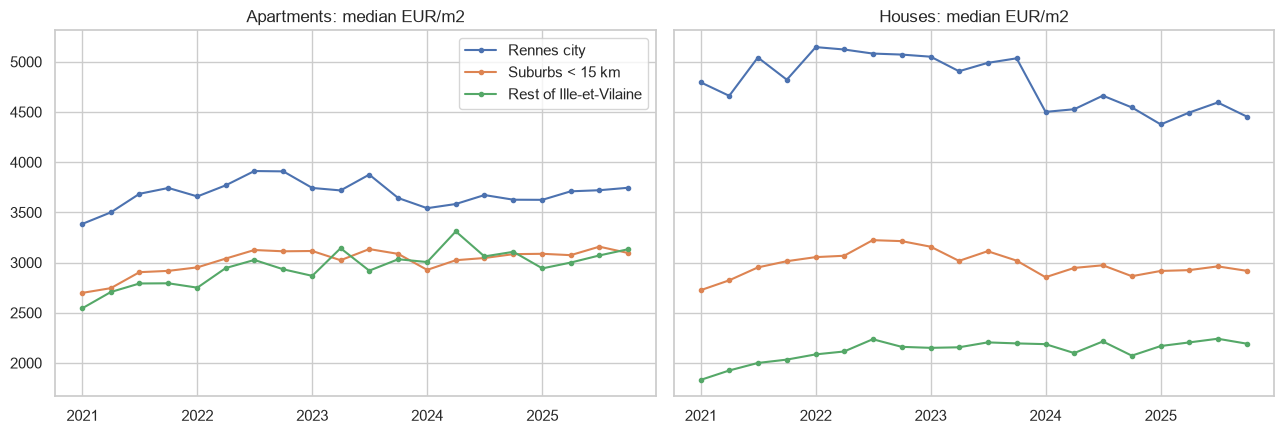

year
2021    15898
2022    15088
2023    12109
2024    11169
2025    12884


type_local,Appartement,Maison
zone,,
Rennes city,3706.0,4490.0
Rest of Ille-et-Vilaine,3055.0,2203.0
Suburbs < 15 km,3112.0,2928.0


In [4]:
q = df.groupby(["quarter", "zone", "type_local"])["eur_m2"].median().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, tipo, titulo in zip(axes, ["Appartement", "Maison"], ["Apartments", "Houses"]):
    for z in ["Rennes city", "Suburbs < 15 km", "Rest of Ille-et-Vilaine"]:
        g = q[(q["type_local"] == tipo) & (q["zone"] == z)]
        ax.plot(g["quarter"].dt.to_timestamp(), g["eur_m2"], marker="o", ms=3, label=z)
    ax.set_title(titulo + ": median EUR/m2")
axes[0].legend()
plt.tight_layout()
plt.savefig("figures/price_m2.png", bbox_inches="tight")
plt.show()

print(df.groupby("year").size().to_string())
df[df["year"] == df["year"].max()].groupby(["zone", "type_local"])["eur_m2"].median().round(0).unstack()

## Part 5. Sales vs mortgage rates

Mortgage rate: minimum 2021-12 1.11 | maximum 2023-12 3.6


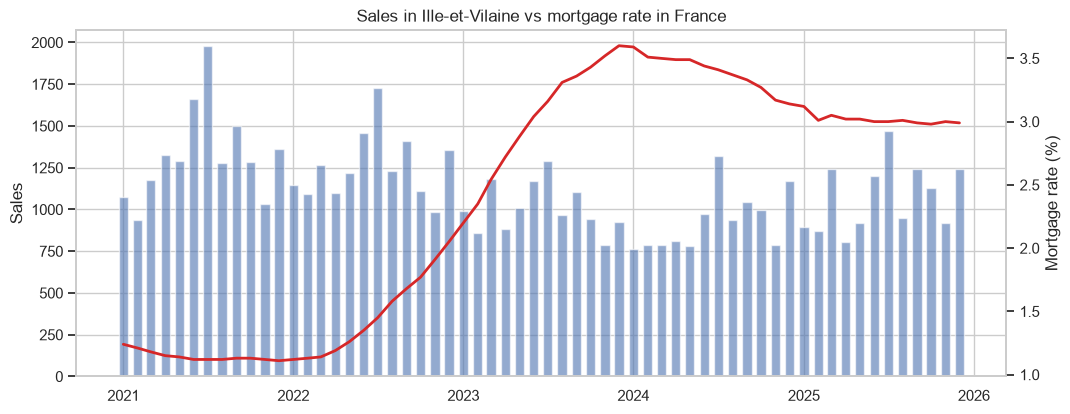

In [5]:
tasa = pd.read_csv("https://data-api.ecb.europa.eu/service/data/MIR/M.FR.B.A2C.A.R.A.2250.EUR.N?format=csvdata")
tasa = tasa.set_index(pd.PeriodIndex(tasa["TIME_PERIOD"], freq="M"))["OBS_VALUE"]
mensual = df.groupby(df["date_mutation"].dt.to_period("M")).size()
datos = pd.DataFrame({"sales": mensual, "rate": tasa}).dropna()
print("Mortgage rate: minimum", tasa.loc["2019":].idxmin(), round(tasa.loc["2019":].min(), 2), "| maximum", tasa.loc["2019":].idxmax(), round(tasa.loc["2019":].max(), 2))

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(datos.index.to_timestamp(), datos["sales"], width=20, alpha=0.6, label="sales per month")
ax1.set_ylabel("Sales")
ax2 = ax1.twinx()
ax2.plot(datos.index.to_timestamp(), datos["rate"], color="tab:red", lw=2, label="mortgage rate")
ax2.set_ylabel("Mortgage rate (%)")
ax2.grid(False)
ax1.set_title("Sales in Ille-et-Vilaine vs mortgage rate in France")
plt.savefig("figures/sales_vs_rate.png", bbox_inches="tight")
plt.show()

In [6]:
# change in 12 months of the (3-month) sales vs change in 12 months of the rate
datos["dlog_sales"] = np.log(datos["sales"].rolling(3).sum()).diff(12)
datos["d_rate"] = datos["rate"].diff(12)
m = smf.ols("dlog_sales ~ d_rate", datos.dropna()).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
print(m.summary().tables[1])
print("R2:", round(m.rsquared, 2))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0287      0.026      1.112      0.266      -0.022       0.079
d_rate        -0.1739      0.024     -7.209      0.000      -0.221      -0.127
R2: 0.76


Every +1 point of mortgage rate in one year goes with around 17% less sales. The adjustment came by the quantity of sales and not by the prices: the owners preferred not to sell instead of lowering the price.

## Part 6. Hedonic model

log(price) = log(surface) + rooms + type + distance band + year

In [7]:
h = df.dropna(subset=["nombre_pieces_principales"]).copy()
h["log_price"] = np.log(h["valeur_fonciere"])
h["log_surface"] = np.log(h["surface_reelle_bati"])
h["rooms"] = h["nombre_pieces_principales"].clip(1, 8)
h["distance"] = pd.cut(h["km"], [0, 3, 6, 10, 15, 25, 40, 200], right=False).astype(str)
hed = smf.ols("log_price ~ log_surface + rooms + C(type_local) + C(distance, Treatment('[0, 3)')) + C(year)", h).fit(cov_type="HC1")
print("R2:", round(hed.rsquared, 3))
print("Surface elasticity:", round(hed.params["log_surface"], 3))
efectos = (np.exp(hed.params.filter(like="C(")) - 1) * 100
efectos.round(1)

R2: 0.541
Surface elasticity: 0.722


C(type_local)[T.Maison]                          -3.1
C(distance, Treatment('[0, 3)'))[T.[10, 15)]    -22.1
C(distance, Treatment('[0, 3)'))[T.[15, 25)]    -33.5
C(distance, Treatment('[0, 3)'))[T.[25, 40)]    -47.9
C(distance, Treatment('[0, 3)'))[T.[3, 6)]      -12.0
C(distance, Treatment('[0, 3)'))[T.[40, 200)]   -26.7
C(distance, Treatment('[0, 3)'))[T.[6, 10)]     -15.2
C(year)[T.2022]                                   9.1
C(year)[T.2023]                                   8.9
C(year)[T.2024]                                   5.9
C(year)[T.2025]                                   8.9
dtype: float64

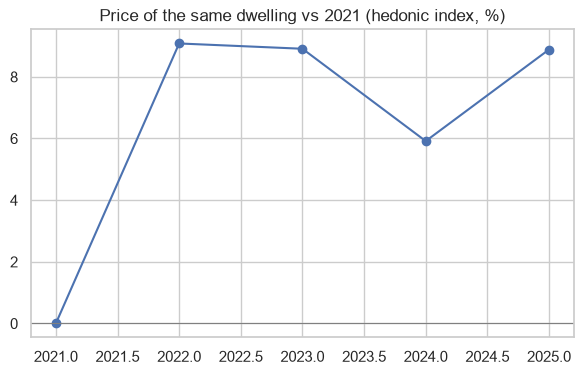

In [8]:
anios = [int(i.split("T.")[1].rstrip("]")) for i in efectos.filter(like="year").index]
plt.figure(figsize=(7, 4))
plt.plot([h["year"].min()] + anios, [0] + list(efectos.filter(like="year").values), marker="o")
plt.axhline(0, color="grey", lw=0.8)
plt.title("Price of the same dwelling vs 2021 (hedonic index, %)")
plt.savefig("figures/hedonic_index.png", bbox_inches="tight")
plt.show()

## Conclusions

- Between 2021 and 2024 the number of sales fell around 30%, while the median prices in Rennes almost did not move. In 2025 sales started to recover.
- The quality-adjusted price (same surface, rooms, type and location) is still around 9% above 2021.
- Location is very important: compared with a dwelling in the centre (less than 3 km from the town hall), the same dwelling costs around 12% less at 3-6 km and almost half at 25-40 km. After 40 km the discount is smaller because of the coast (Saint-Malo, Dinard).